# Multiple Linear Regression — Student Performance

This notebook builds and evaluates multiple linear regression models (OLS, Ridge, Lasso) to predict student performance using the [Student Performance dataset](https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression).

**Features used:**
- `hours_studied` — daily study hours
- `previous_scores` — scores from previous exams
- `sleep_hours` — average sleep per night
- `sample_question_papers_practiced` — practice papers completed
- `extracurricular_activities` — encoded binary (Yes=1, No=0)

**Target:** `performance_index` (0–100)

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')


## 2. Load and Inspect Data

In [2]:
df = pd.read_csv('Student_Performance.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [3]:
df1 = df.copy()

### 2.1 Data Quality: Duplicates & Missing Values

Exact duplicate rows are a source of **train/test leakage**: if the same row lands in both the training and test set, the model is evaluated on data it has already seen, which inflates test scores. They are removed **before** splitting.

In [4]:
print(f"Missing values : {df1.isna().sum().sum()}")
print(f"Duplicate rows : {df1.duplicated().sum()}")

df1 = df1.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df1.shape}")

Missing values : 0
Duplicate rows : 127
Shape after removing duplicates: (9873, 6)


In [5]:
df1.head(
    
)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


## 3. Preprocessing

### 3.1 Encode Categorical Variable

Encode `Extracurricular Activities` (Yes/No) as a numeric binary column using `pd.Categorical`.

In [6]:
df1['extracurricular_activities'] = pd.Categorical(df1['Extracurricular Activities']).codes
df1['extracurricular_activities'].head(10)

0    1
1    0
2    1
3    1
4    0
5    0
6    1
7    1
8    0
9    0
Name: extracurricular_activities, dtype: int8

In [7]:
df1 = df1.drop('Extracurricular Activities', axis =1)

### 3.2 Standardise Column Names

Convert all column names to lowercase with underscores for consistency.

In [8]:
df1.head(10)

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,extracurricular_activities
0,7,99,9,1,91.0,1
1,4,82,4,2,65.0,0
2,8,51,7,2,45.0,1
3,5,52,5,2,36.0,1
4,7,75,8,5,66.0,0
5,3,78,9,6,61.0,0
6,7,73,5,6,63.0,1
7,8,45,4,6,42.0,1
8,5,77,8,2,61.0,0
9,4,89,4,0,69.0,0


In [9]:
df1.columns = df1.columns.str.replace(' ','_').str.lower()
df1.head(10)

,hours_studied,previous_scores,sleep_hours,sample_question_papers_practiced,performance_index,extracurricular_activities
0,7,99,9,1,91.0,1
1,4,82,4,2,65.0,0
2,8,51,7,2,45.0,1
3,5,52,5,2,36.0,1
4,7,75,8,5,66.0,0
5,3,78,9,6,61.0,0
6,7,73,5,6,63.0,1
7,8,45,4,6,42.0,1
8,5,77,8,2,61.0,0
9,4,89,4,0,69.0,0


## 4. Exploratory Data Analysis

### 4.1 Pairplot

Visualise the relationship between each feature and the target `performance_index`.

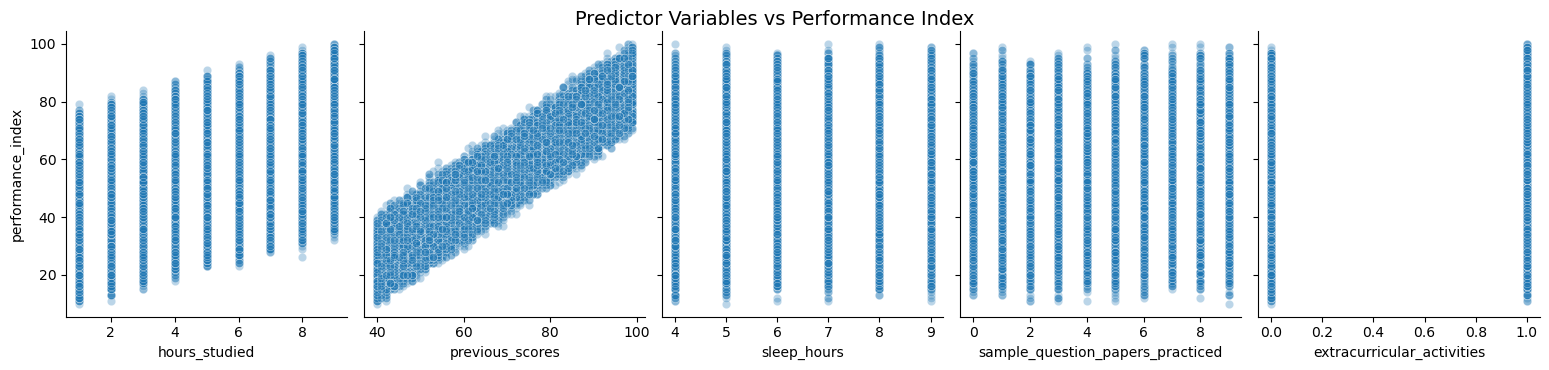

In [10]:
# Pairplot of features vs target
sns.pairplot(df1, x_vars=['hours_studied', 'previous_scores', 'sleep_hours', 'sample_question_papers_practiced', 'extracurricular_activities'], 
             y_vars=['performance_index'], height=3.5, aspect=0.9, plot_kws={'alpha': 0.3, 'color': '#1f77b4'})
plt.suptitle('Predictor Variables vs Performance Index', y=1.03, fontsize=14)
plt.show()


### 4.2 Correlation Matrix

Pearson correlation to quantify linear relationships between all numeric features.

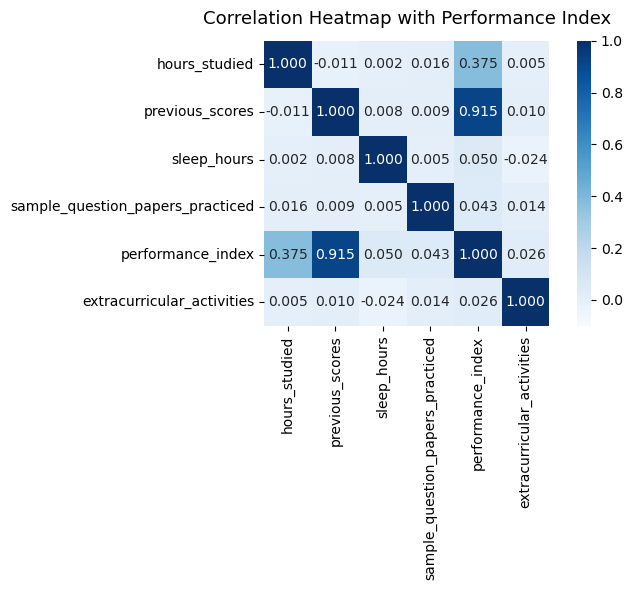


Correlation with Performance Index:
performance_index                   1.000000
previous_scores                     0.915135
hours_studied                       0.375332
sleep_hours                         0.050352
sample_question_papers_practiced    0.043436
extracurricular_activities          0.026075
Name: performance_index, dtype: float64


In [11]:
# Pearson correlation heatmap
correlation_matrix = df1.corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt='.3f', cmap='Blues', vmin=-0.1, vmax=1.0, square=True)
plt.title('Correlation Heatmap with Performance Index', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

print("\nCorrelation with Performance Index:")
print(correlation_matrix['performance_index'].sort_values(ascending=False))


### 4.3 Multicollinearity Check (VIF)

Variance Inflation Factor computed with an intercept. VIF < 5 indicates no problematic collinearity.

In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

vif_features = ['hours_studied', 'previous_scores', 'sleep_hours',
                'sample_question_papers_practiced', 'extracurricular_activities']
X_vif = add_constant(df1[vif_features].astype(float))
vif = pd.DataFrame({
    'Feature': vif_features,
    'VIF': [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(vif_features))]
})
print(vif.to_string(index=False))

                         Feature      VIF
                   hours_studied 1.000393
                 previous_scores 1.000350
                     sleep_hours 1.000676
sample_question_papers_practiced 1.000540
      extracurricular_activities 1.000888


## 5. Model Training

### 5.1 Train/Test Split and Baseline Linear Regression

In [13]:
# 5.1 Train/Test Split & Linear Regression with all 5 features
feature = ['hours_studied', 'previous_scores', 'sleep_hours', 'sample_question_papers_practiced', 'extracurricular_activities']
X = df1[feature]
y = df1['performance_index']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Train baseline OLS model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_predict = model.predict(X_test)

# Evaluation metrics
mse = mean_squared_error(y_test, y_predict)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_predict)
r2 = r2_score(y_test, y_predict)

print("="*45)
print("BASELINE LINEAR REGRESSION (5 FEATURES)")
print("="*45)
print(f"Test MSE : {mse:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test R²  : {r2:.6f}")
print("\nModel Coefficients:")
for col, coef in zip(feature, model.coef_):
    print(f"  {col:<35}: {coef:>+.4f}")
print(f"  {'Intercept':<35}: {model.intercept_:>+.4f}")


BASELINE LINEAR REGRESSION (5 FEATURES)
Test MSE : 4.3059
Test RMSE: 2.0751
Test MAE : 1.6470
Test R²  : 0.988430

Model Coefficients:
  hours_studied                      : +2.8510
  previous_scores                    : +1.0184
  sleep_hours                        : +0.4721
  sample_question_papers_practiced   : +0.1887
  extracurricular_activities         : +0.5738
  Intercept                          : -33.9813


### 5.1.1 Does `extracurricular_activities` Help?

Compare the 4-feature model (without extracurricular activities) against the 5-feature model on the same split.

In [14]:
feature_4 = [f for f in feature if f != 'extracurricular_activities']
model_4 = LinearRegression().fit(X_train[feature_4], y_train)
y_pred_4 = model_4.predict(X_test[feature_4])

comparison = pd.DataFrame({
    'Model': ['4 features (no extracurricular)', '5 features'],
    'Test MSE': [mean_squared_error(y_test, y_pred_4), mse],
    'Test R²': [r2_score(y_test, y_pred_4), r2],
})
print(comparison.to_string(index=False))

                          Model  Test MSE  Test R²
4 features (no extracurricular)  4.449347 0.988045
                     5 features  4.305901 0.988430


### 5.2 Residual Analysis

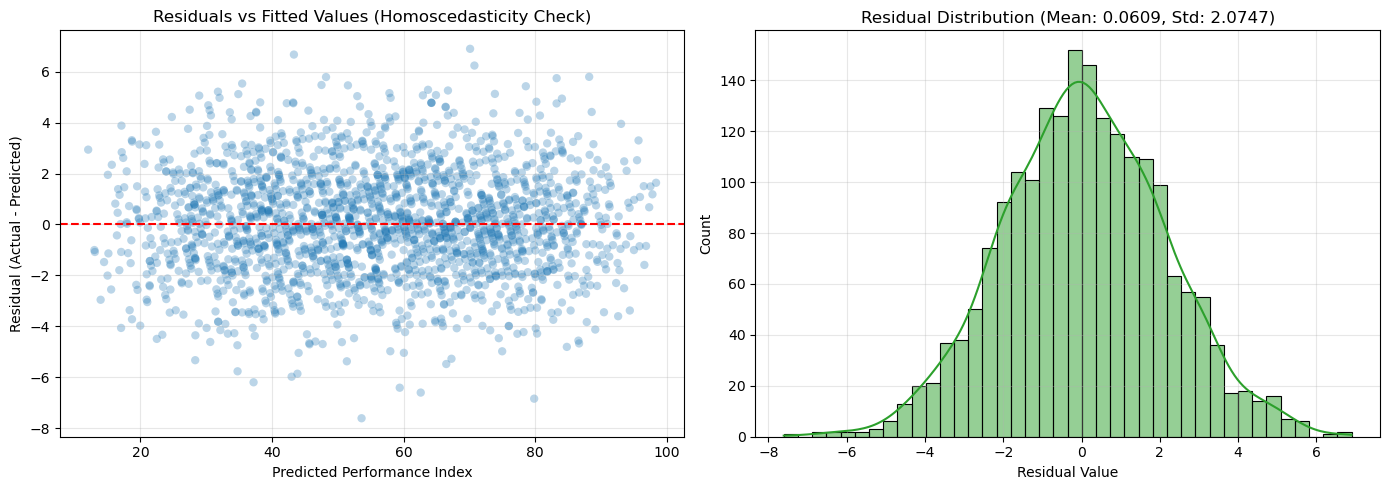

In [15]:
# Residual Diagnostics
residuals = y_test - y_predict

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Predicted vs Residuals
axes[0].scatter(y_predict, residuals, alpha=0.3, color='#1f77b4', edgecolors='none')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Predicted Performance Index')
axes[0].set_ylabel('Residual (Actual - Predicted)')
axes[0].set_title('Residuals vs Fitted Values (Homoscedasticity Check)')
axes[0].grid(True, alpha=0.3)

# Plot 2: Residual distribution (Normality)
sns.histplot(residuals, kde=True, ax=axes[1], color='#2ca02c', bins=40)
axes[1].set_xlabel('Residual Value')
axes[1].set_title(f'Residual Distribution (Mean: {residuals.mean():.4f}, Std: {residuals.std():.4f})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 5.3 Ridge Regression

Ridge adds an L2 penalty to shrink coefficients and reduce overfitting.

In [16]:
# Create Ridge pipeline with StandardScaler & Cross-Validated alpha search
alphas = np.logspace(-3, 3, 50)
ridge_cv = RidgeCV(alphas=alphas, cv=5)

# Standardize features before applying L2 penalty
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ridge_cv.fit(X_train_scaled, y_train)

# Predict
y_ridge = ridge_cv.predict(X_test_scaled)

# Evaluate
mse_ridge = mean_squared_error(y_test, y_ridge)
rmse_ridge = np.sqrt(mse_ridge)
mae_ridge = mean_absolute_error(y_test, y_ridge)
r2_ridge = r2_score(y_test, y_ridge)

print("="*45)
print("RIDGE REGRESSION (WITH SCALING & CV TUNING)")
print("="*45)
print(f"Optimal Alpha : {ridge_cv.alpha_:.4f}")
print(f"Test MSE      : {mse_ridge:.4f}")
print(f"Test RMSE     : {rmse_ridge:.4f}")
print(f"Test MAE      : {mae_ridge:.4f}")
print(f"Test R²       : {r2_ridge:.6f}")


RIDGE REGRESSION (WITH SCALING & CV TUNING)
Optimal Alpha : 0.0010
Test MSE      : 4.3059
Test RMSE     : 2.0751
Test MAE      : 1.6470
Test R²       : 0.988430


### 5.4 Lasso Regression

Lasso adds an L1 penalty which can zero out irrelevant features (implicit feature selection).

In [17]:
# Create Lasso pipeline with StandardScaler & Cross-Validated alpha search
lasso_cv = LassoCV(alphas=np.logspace(-4, 1, 50), cv=5, max_iter=10000, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)

# Predict
y_lasso = lasso_cv.predict(X_test_scaled)

# Evaluate
mse_lasso = mean_squared_error(y_test, y_lasso)
rmse_lasso = np.sqrt(mse_lasso)
mae_lasso = mean_absolute_error(y_test, y_lasso)
r2_lasso = r2_score(y_test, y_lasso)

print("="*45)
print("LASSO REGRESSION (WITH SCALING & CV TUNING)")
print("="*45)
print(f"Optimal Alpha : {lasso_cv.alpha_:.6f}")
print(f"Test MSE      : {mse_lasso:.4f}")
print(f"Test RMSE     : {rmse_lasso:.4f}")
print(f"Test MAE      : {mae_lasso:.4f}")
print(f"Test R²       : {r2_lasso:.6f}")
print(f"Active Features: {(lasso_cv.coef_ != 0).sum()} of {len(feature)}")


LASSO REGRESSION (WITH SCALING & CV TUNING)
Optimal Alpha : 0.000324
Test MSE      : 4.3061
Test RMSE     : 2.0751
Test MAE      : 1.6470
Test R²       : 0.988430
Active Features: 5 of 5


## 6. Model Comparison

Overlay predicted vs actual values for all three models to compare performance visually.

MODEL PERFORMANCE COMPARISON
            Model Best Alpha  Test MSE  Test RMSE  Test MAE  Test R² 5-Fold CV R² (Mean ± Std)
Linear Regression        N/A  4.305901   2.075066  1.646970  0.98843       0.988659 ± 0.000242
 Ridge Regression     0.0010  4.305901   2.075066  1.646970  0.98843       0.988659 ± 0.000242
 Lasso Regression   0.000324  4.306073   2.075108  1.647002  0.98843       0.988659 ± 0.000243


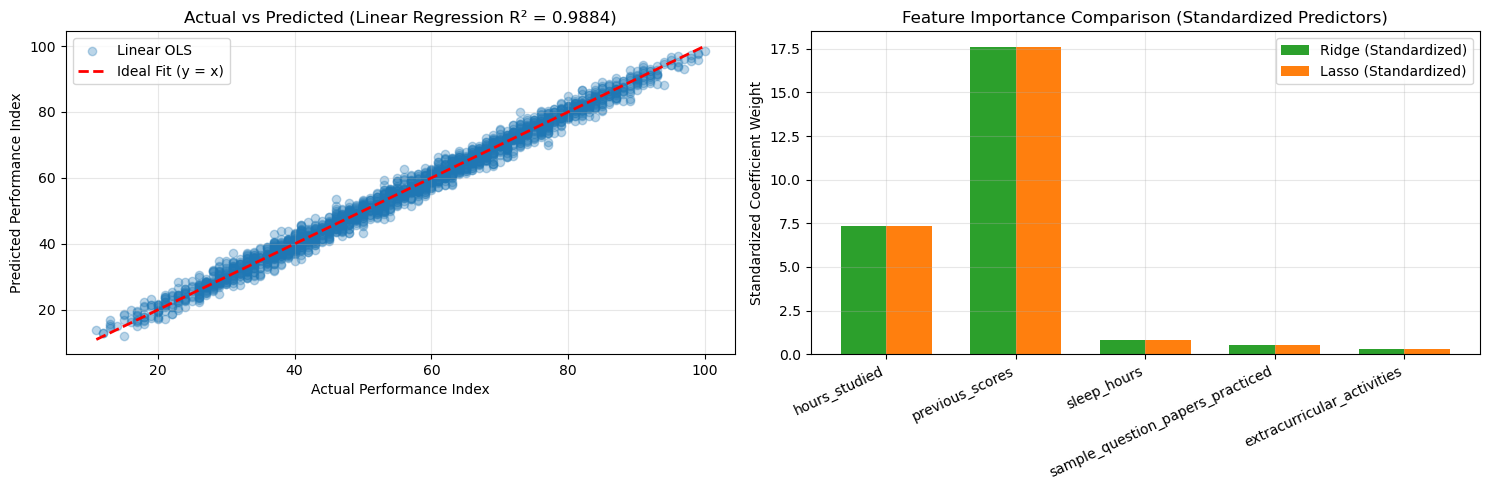

In [18]:
# Comprehensive Model Comparison & 5-Fold Cross Validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# CV scores
lr_cv_scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2')
ridge_cv_scores = cross_val_score(Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=ridge_cv.alpha_))]), X, y, cv=cv, scoring='r2')
lasso_cv_scores = cross_val_score(Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(alpha=lasso_cv.alpha_))]), X, y, cv=cv, scoring='r2')

# Summary comparison table
summary_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'Best Alpha': ['N/A', f"{ridge_cv.alpha_:.4f}", f"{lasso_cv.alpha_:.6f}"],
    'Test MSE': [mse, mse_ridge, mse_lasso],
    'Test RMSE': [rmse, rmse_ridge, rmse_lasso],
    'Test MAE': [mae, mae_ridge, mae_lasso],
    'Test R²': [r2, r2_ridge, r2_lasso],
    '5-Fold CV R² (Mean ± Std)': [
        f"{lr_cv_scores.mean():.6f} ± {lr_cv_scores.std():.6f}",
        f"{ridge_cv_scores.mean():.6f} ± {ridge_cv_scores.std():.6f}",
        f"{lasso_cv_scores.mean():.6f} ± {lasso_cv_scores.std():.6f}"
    ]
})

print("="*85)
print("MODEL PERFORMANCE COMPARISON")
print("="*85)
print(summary_df.to_string(index=False))

# Visualization: Actual vs Predicted & Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Actual vs Predicted with ideal 45-degree line
axes[0].scatter(y_test, y_predict, alpha=0.3, label='Linear OLS', color='#1f77b4')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Ideal Fit (y = x)')
axes[0].set_xlabel('Actual Performance Index')
axes[0].set_ylabel('Predicted Performance Index')
axes[0].set_title(f'Actual vs Predicted (Linear Regression R² = {r2:.4f})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Standardized Feature Importances (Coefficients)
std_coefs = pd.DataFrame({
    'Feature': feature,
    'OLS (Unscaled)': model.coef_,
    'Ridge (Scaled)': ridge_cv.coef_,
    'Lasso (Scaled)': lasso_cv.coef_
})

x_idx = np.arange(len(feature))
width = 0.35
axes[1].bar(x_idx - width/2, ridge_cv.coef_, width, label='Ridge (Standardized)', color='#2ca02c')
axes[1].bar(x_idx + width/2, lasso_cv.coef_, width, label='Lasso (Standardized)', color='#ff7f0e')
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(feature, rotation=25, ha='right')
axes[1].set_ylabel('Standardized Coefficient Weight')
axes[1].set_title('Feature Importance Comparison (Standardized Predictors)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Summary & Key Findings

**Data quality:** 127 exact duplicate rows were removed before the train/test split (10,000 → 9,873 rows). Before this fix, 47 test rows were exact copies of training rows, which leaked information and slightly inflated the scores (Test R² 0.98898 → 0.98843 after the fix). No missing values; no feature is derived from the target.

| Model | Hyperparameters | Test RMSE | Test MAE | Test R² | 5-Fold CV R² |
|---|---|---|---|---|---|
| **Linear Regression** | Baseline OLS | 2.0751 | 1.6470 | 0.98843 | 0.98866 ± 0.00024 |
| **Ridge Regression** | α = 0.001 (CV) | 2.0751 | 1.6470 | 0.98843 | 0.98866 ± 0.00024 |
| **Lasso Regression** | α = 0.000324 (CV) | 2.0751 | 1.6470 | 0.98843 | 0.98866 ± 0.00024 |

### Key Takeaways
1. **Feature inclusion:** adding `extracurricular_activities` lowers test MSE from **4.449 to 4.306** (R² 0.98805 → 0.98843). Participation is associated with about **+0.57 points** on the performance index, holding other factors constant.
2. **Dominant drivers:** `previous_scores` (r = 0.915, β ≈ 1.018 per point) and `hours_studied` (β ≈ 2.851 per hour) explain most of the variance. Each additional hour of study is associated with roughly 2.85 more points.
3. **Regularization:** all VIFs are ≈ 1.00 (no multicollinearity) and every predictor carries signal, so Ridge and Lasso converge to the OLS solution. Regularization adds nothing here.
4. **Generalization:** test R² and 5-fold CV R² agree closely, with very low variance across folds.
5. **Caveat:** an R² near 0.99 is unusual for real-world education data. This dataset is synthetic and almost perfectly linear, so these results show the method works, not that real student outcomes are this predictable.
